In [2]:

# CREDIT CARD FRAUD DETECTION PROJECT
#Import Libraries


# Import NumPy for numerical operations
import numpy as np

# Import Pandas for data manipulation
import pandas as pd

# Import Matplotlib for plotting graphs
import matplotlib.pyplot as plt

# Import Seaborn for better visualizations
import seaborn as sns

# Display graphs inside the notebook
%matplotlib inline

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [3]:

# Load the Dataset

# Read the CSV file
df = pd.read_csv("../dataset/creditcard.csv")

# Display the first 5 rows
df.head()


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df.shape


(284807, 31)

In [5]:

# Dataset Information


# Display number of rows and columns
print("Dataset Shape:")
print(df.shape)

# Display information about columns
print("\nDataset Information:")
df.info()

Dataset Shape:
(284807, 31)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     2

In [6]:
# Display all column names

df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [7]:
# ==========================================
# Checking Missing Values
# ==========================================

missing_values = df.isnull().sum()

missing_values

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [8]:
# ==========================================
# Checking Duplicate Rows
# ==========================================

duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 1081


In [9]:
# ==========================================
# Statistical Summary
# ==========================================

df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [10]:
# ==========================================
# Fraud vs Genuine Transaction Count
# ==========================================

class_counts = df['Class'].value_counts()

print(class_counts)

Class
0    284315
1       492
Name: count, dtype: int64


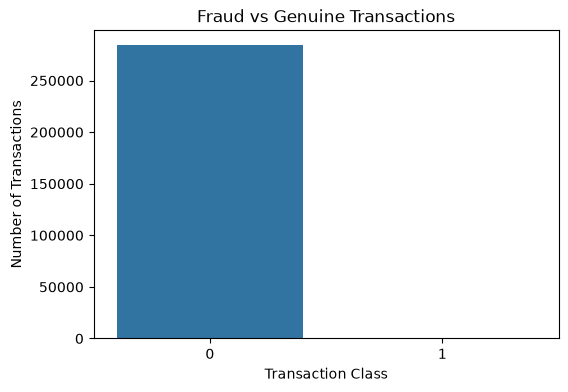

In [11]:
# ==========================================
# Fraud Distribution Visualization
# ==========================================

plt.figure(figsize=(6,4))

sns.countplot(
    x='Class',
    data=df
)

plt.title("Fraud vs Genuine Transactions")

plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.show()

In [12]:
# ==========================================
# Fraud Percentage
# ==========================================

fraud_percentage = (
    df['Class'].value_counts()[1] /
    len(df)
) * 100


print(
    "Fraud Transactions Percentage:",
    fraud_percentage
)

Fraud Transactions Percentage: 0.1727485630620034


In [13]:
# ==========================================
# Transaction Amount Statistics
# ==========================================

df['Amount'].describe()

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

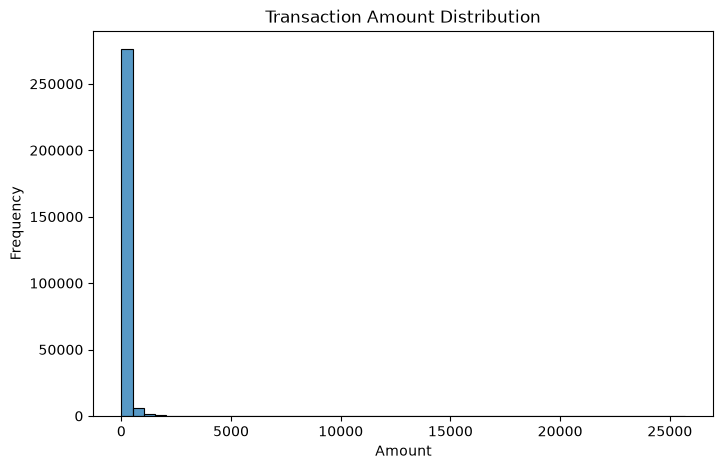

In [14]:
# ==========================================
# Transaction Amount Distribution
# ==========================================

plt.figure(figsize=(8,5))

sns.histplot(
    df['Amount'],
    bins=50
)

plt.title("Transaction Amount Distribution")

plt.xlabel("Amount")

plt.ylabel("Frequency")

plt.show()

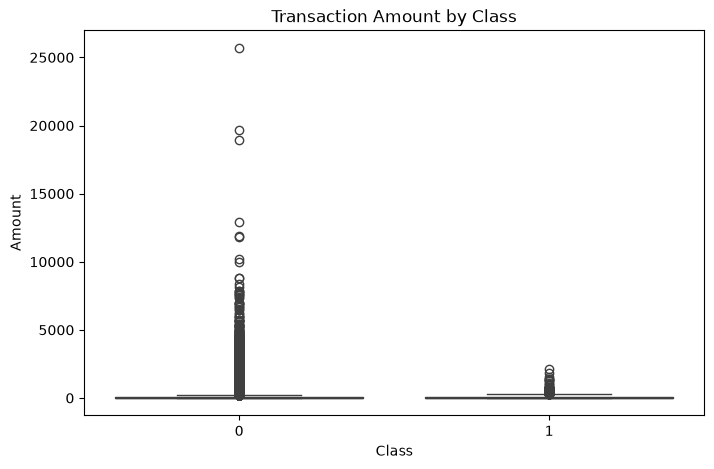

In [15]:
# ==========================================
# Amount Comparison
# ==========================================

plt.figure(figsize=(8,5))

sns.boxplot(
    x='Class',
    y='Amount',
    data=df
)

plt.title(
    "Transaction Amount by Class"
)

plt.show()

In [16]:
# ==========================================
# Remove Duplicate Rows
# ==========================================

print("Shape Before Removing Duplicates:", df.shape)

df = df.drop_duplicates()

print("Shape After Removing Duplicates:", df.shape)

Shape Before Removing Duplicates: (284807, 31)
Shape After Removing Duplicates: (283726, 31)


In [17]:
# ==========================================
# Separate Features and Target
# ==========================================

X = df.drop("Class", axis=1)

y = df["Class"]

print("Features Shape :", X.shape)
print("Target Shape   :", y.shape)

Features Shape : (283726, 30)
Target Shape   : (283726,)


In [18]:
# ==========================================
# Scale Amount Column
# ==========================================

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X["Amount"] = scaler.fit_transform(X[["Amount"]])

print("Amount column scaled successfully.")

Amount column scaled successfully.


In [19]:
# ==========================================
# Train-Test Split
# ==========================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features :", X_train.shape)
print("Testing Features  :", X_test.shape)

print("Training Labels   :", y_train.shape)
print("Testing Labels    :", y_test.shape)

Training Features : (226980, 30)
Testing Features  : (56746, 30)
Training Labels   : (226980,)
Testing Labels    : (56746,)


In [20]:
# ==========================================
# Class Distribution Before SMOTE
# ==========================================

print(y_train.value_counts())

Class
0    226602
1       378
Name: count, dtype: int64


In [21]:
# ==========================================
# Apply SMOTE
# ==========================================

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE")
print(y_train.value_counts())

print("\nAfter SMOTE")
print(y_train_smote.value_counts())

Before SMOTE
Class
0    226602
1       378
Name: count, dtype: int64

After SMOTE
Class
0    226602
1    226602
Name: count, dtype: int64


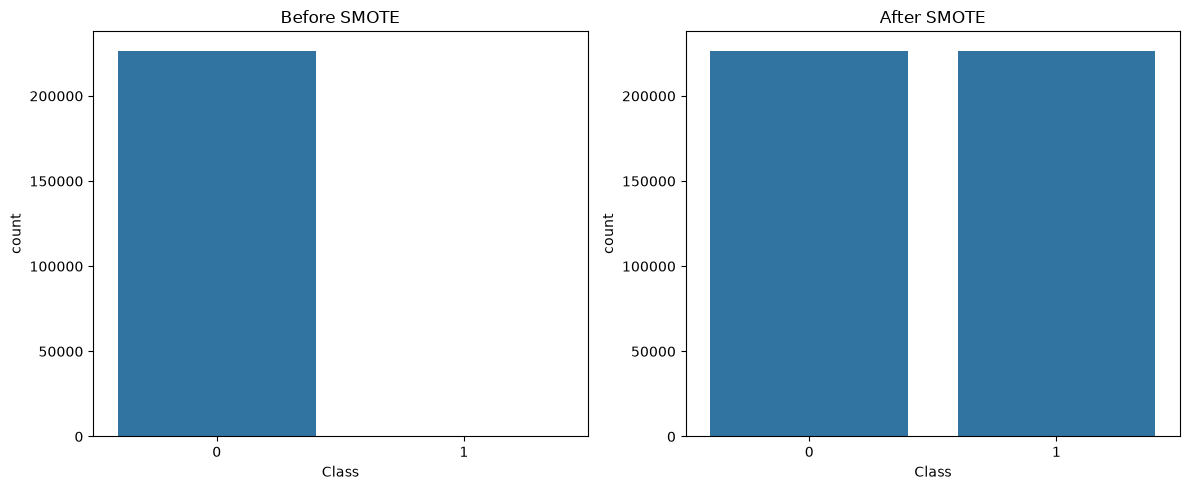

In [22]:
# ==========================================
# Compare Before and After SMOTE
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x=y_train, ax=axes[0])
axes[0].set_title("Before SMOTE")

sns.countplot(x=y_train_smote, ax=axes[1])
axes[1].set_title("After SMOTE")

plt.tight_layout()

plt.show()

In [23]:
# ==========================================
# Import Logistic Regression
# ==========================================

from sklearn.linear_model import LogisticRegression

# Create the model
lr_model = LogisticRegression(random_state=42)

print("Logistic Regression Model Created Successfully!")

Logistic Regression Model Created Successfully!


In [24]:
# ==========================================
# Train Logistic Regression Model
# ==========================================

lr_model.fit(X_train_smote, y_train_smote)

print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [25]:
# ==========================================
# Predict on Test Data
# ==========================================

y_pred = lr_model.predict(X_test)

print("Prediction Completed!")

print("\nFirst 20 Predictions:")

print(y_pred[:20])

Prediction Completed!

First 20 Predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [26]:
# ==========================================
# Accuracy Score
# ==========================================

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy :", accuracy)

Accuracy : 0.9875057272759313


In [27]:
# ==========================================
# Classification Report
# ==========================================

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56651
           1       0.10      0.84      0.18        95

    accuracy                           0.99     56746
   macro avg       0.55      0.91      0.59     56746
weighted avg       1.00      0.99      0.99     56746



In [28]:
# ==========================================
# Confusion Matrix
# ==========================================

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[55957   694]
 [   15    80]]


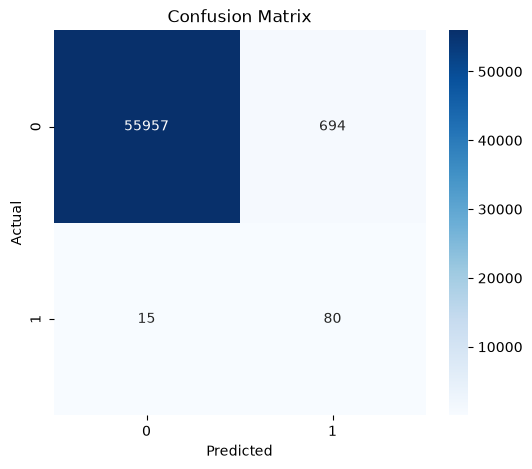

In [29]:
# ==========================================
# Confusion Matrix Heatmap
# ==========================================

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [30]:
# ==========================================
# ROC AUC Score
# ==========================================

from sklearn.metrics import roc_auc_score

roc_score = roc_auc_score(y_test, y_pred)

print("ROC AUC Score :", roc_score)

ROC AUC Score : 0.9149274087232167


In [31]:
# ==========================================
# Import Decision Tree
# ==========================================

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

print("Decision Tree Model Created Successfully!")

Decision Tree Model Created Successfully!


In [32]:
# ==========================================
# Train Decision Tree
# ==========================================

dt_model.fit(
    X_train_smote,
    y_train_smote
)

print("Decision Tree Training Completed!")

Decision Tree Training Completed!


In [33]:
# ==========================================
# Predict Using Decision Tree
# ==========================================

dt_pred = dt_model.predict(X_test)

print("Prediction Completed!")

Prediction Completed!


In [34]:
# ==========================================
# Decision Tree Accuracy
# ==========================================

from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(
    y_test,
    dt_pred
)

print("Decision Tree Accuracy :", dt_accuracy)

Decision Tree Accuracy : 0.9982025164769323


In [35]:
# ==========================================
# Classification Report
# ==========================================

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    dt_pred
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.48      0.75      0.58        95

    accuracy                           1.00     56746
   macro avg       0.74      0.87      0.79     56746
weighted avg       1.00      1.00      1.00     56746



In [36]:
# ==========================================
# Confusion Matrix
# ==========================================

from sklearn.metrics import confusion_matrix

dt_cm = confusion_matrix(
    y_test,
    dt_pred
)

print(dt_cm)

[[56573    78]
 [   24    71]]


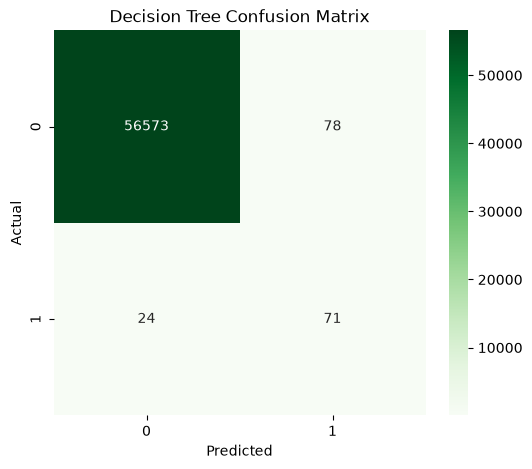

In [37]:
# ==========================================
# Decision Tree Heatmap
# ==========================================

plt.figure(figsize=(6,5))

sns.heatmap(
    dt_cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Decision Tree Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [38]:
# ==========================================
# ROC AUC
# ==========================================

from sklearn.metrics import roc_auc_score

dt_roc = roc_auc_score(
    y_test,
    dt_pred
)

print("Decision Tree ROC AUC :", dt_roc)

Decision Tree ROC AUC : 0.8729957849027611


In [39]:
# ==========================================
# Import Random Forest
# ==========================================

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

print("Random Forest Model Created Successfully!")

Random Forest Model Created Successfully!


In [40]:
# ==========================================
# Train Random Forest
# ==========================================

rf_model.fit(
    X_train_smote,
    y_train_smote
)

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [41]:
# ==========================================
# Predict Using Random Forest
# ==========================================

rf_pred = rf_model.predict(X_test)

print("Prediction Completed!")

Prediction Completed!


In [42]:
# ==========================================
# Random Forest Accuracy
# ==========================================

from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(
    y_test,
    rf_pred
)

print("Random Forest Accuracy :", rf_accuracy)

Random Forest Accuracy : 0.9994889507630493


In [43]:
# ==========================================
# Classification Report
# ==========================================

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    rf_pred
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.91      0.77      0.83        95

    accuracy                           1.00     56746
   macro avg       0.96      0.88      0.92     56746
weighted avg       1.00      1.00      1.00     56746



In [44]:
# ==========================================
# Confusion Matrix
# ==========================================

from sklearn.metrics import confusion_matrix

rf_cm = confusion_matrix(
    y_test,
    rf_pred
)

print(rf_cm)

[[56644     7]
 [   22    73]]


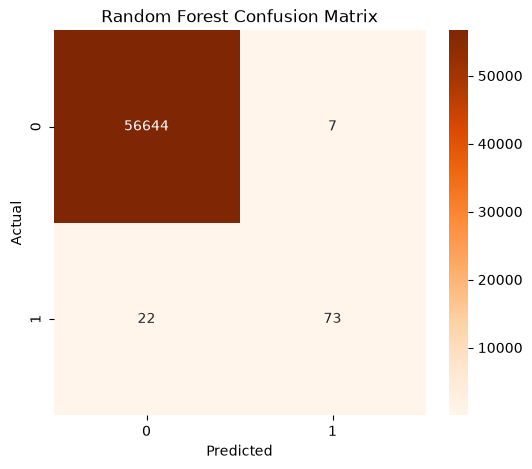

In [45]:
# ==========================================
# Random Forest Heatmap
# ==========================================

plt.figure(figsize=(6,5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [46]:
# ==========================================
# ROC AUC
# ==========================================

from sklearn.metrics import roc_auc_score

rf_roc = roc_auc_score(
    y_test,
    rf_pred
)

print("Random Forest ROC AUC :", rf_roc)

Random Forest ROC AUC : 0.8841487445290601


In [47]:
# ==========================================
# Import XGBoost
# ==========================================

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

print("XGBoost Model Created Successfully!")

XGBoost Model Created Successfully!


In [48]:
# ==========================================
# Train XGBoost
# ==========================================

xgb_model.fit(
    X_train_smote,
    y_train_smote
)

print("XGBoost Training Completed!")

XGBoost Training Completed!


In [49]:
# ==========================================
# Predict Using XGBoost
# ==========================================

xgb_pred = xgb_model.predict(X_test)

print("Prediction Completed!")

Prediction Completed!


In [50]:
# ==========================================
# XGBoost Accuracy
# ==========================================

from sklearn.metrics import accuracy_score

xgb_accuracy = accuracy_score(
    y_test,
    xgb_pred
)

print("XGBoost Accuracy :", xgb_accuracy)

XGBoost Accuracy : 0.9993832164381631


In [51]:
# ==========================================
# Classification Report
# ==========================================

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    xgb_pred
))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.83      0.80      0.81        95

    accuracy                           1.00     56746
   macro avg       0.91      0.90      0.91     56746
weighted avg       1.00      1.00      1.00     56746



In [52]:
# ==========================================
# Confusion Matrix
# ==========================================

from sklearn.metrics import confusion_matrix

xgb_cm = confusion_matrix(
    y_test,
    xgb_pred
)

print(xgb_cm)

[[56635    16]
 [   19    76]]


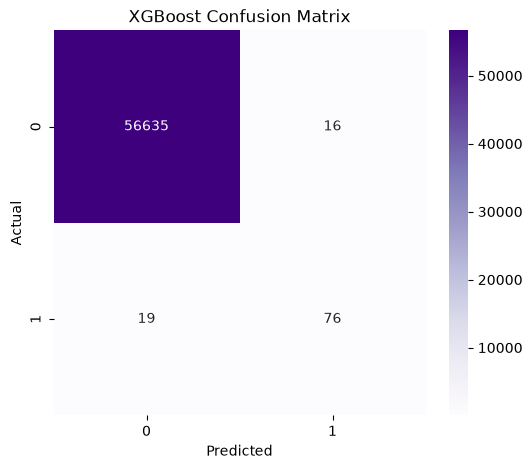

In [53]:
# ==========================================
# XGBoost Heatmap
# ==========================================

plt.figure(figsize=(6,5))

sns.heatmap(
    xgb_cm,
    annot=True,
    fmt="d",
    cmap="Purples"
)

plt.title("XGBoost Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

In [57]:
# ==========================================
# ROC AUC
# ==========================================

from sklearn.metrics import roc_auc_score

xgb_roc = roc_auc_score(
    y_test,
    xgb_pred
)

print("XGBoost ROC AUC :", xgb_roc)

XGBoost ROC AUC : 0.899858784487476
